## Подключение библиотек

In [20]:
# Основные библиотеки
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Torch
import torch
import torchvision.transforms as transforms
from torchvision.transforms import functional as F
from torch.utils.data import Dataset, DataLoader

# Модели
from movinets import MoViNet
from movinets.config import _C

## Подготовка датасетов

In [11]:
class UCF101Dataset(Dataset):
    def __init__(self, csv_file, root_dir='', transform=None, 
                 num_frames=16, frame_rate=5, use_decord=True):
        """
        csv_file: путь к CSV файлу
        root_dir: корневая директория (если пути относительные)
        transform: трансформации
        num_frames: количество кадров
        frame_rate: частота кадров (берем каждый n-й кадр)
        use_decord: использовать ли decord для быстрой загрузки
        """
        self.df = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform
        self.num_frames = num_frames
        self.frame_rate = frame_rate
        self.use_decord = use_decord
        
        # Проверяем и корректируем пути
        self.samples = []
        self.labels = []
        
        for _, row in self.df.iterrows():
            clip_path = row['clip_path']
            label = row['label']
            
            # Если путь начинается с /, убираем начальный слэш
            if clip_path.startswith('/'):
                clip_path = clip_path[1:]
            
            # Полный путь
            full_path = os.path.join(root_dir, clip_path) if root_dir else clip_path
            
            # Проверяем существование файла
            if os.path.exists(full_path):
                self.samples.append(full_path)
                self.labels.append(label)
            else:
                # Пробуем найти файл
                found = False
                for dirpath, _, filenames in os.walk('.'):
                    if os.path.basename(clip_path) in filenames:
                        full_path = os.path.join(dirpath, os.path.basename(clip_path))
                        self.samples.append(full_path)
                        self.labels.append(label)
                        found = True
                        break
                if not found:
                    print(f"Warning: File not found: {full_path}")
        
        # Создаем маппинг меток
        self.classes = sorted(set(self.labels))
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.classes)}
        self.idx_to_class = {idx: cls for idx, cls in enumerate(self.classes)}
        
        # Конвертируем строковые метки в индексы
        self.label_indices = [self.class_to_idx[label] for label in self.labels]
        
        print(f"Loaded {len(self.samples)} samples")
        print(f"Number of classes: {len(self.classes)}")
    
    def __len__(self):
        return len(self.samples)
    
    def load_video_decord(self, video_path):
        """Быстрая загрузка с помощью decord"""
        try:
            import decord
            vr = decord.VideoReader(video_path)
            total_frames = len(vr)
            
            if total_frames == 0:
                return None
            
            # Выбираем кадры равномерно
            indices = np.linspace(0, total_frames-1, self.num_frames, dtype=int)
            frames = vr.get_batch(indices).asnumpy()  # [T, H, W, C]
            return frames
            
        except Exception as e:
            print(f"Decord error for {video_path}: {e}")
            return None
    
    def load_video_opencv(self, video_path):
        """Загрузка с помощью OpenCV"""
        import cv2
        cap = cv2.VideoCapture(video_path)
        frames = []
        frame_count = 0
        
        while len(frames) < self.num_frames:
            ret, frame = cap.read()
            if not ret:
                break
            
            if frame_count % self.frame_rate == 0:
                # BGR -> RGB
                frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frames.append(frame_rgb)
            
            frame_count += 1
        
        cap.release()
        
        if len(frames) == 0:
            return None
        
        # Если кадров недостаточно, дублируем
        if len(frames) < self.num_frames:
            frames = frames + [frames[-1]] * (self.num_frames - len(frames))
        
        return np.array(frames[:self.num_frames])
    
    def __getitem__(self, idx):
        video_path = self.samples[idx]
        label_idx = self.label_indices[idx]
        
        # Загружаем видео
        frames = None
        
        if self.use_decord:
            frames = self.load_video_decord(video_path)
        
        if frames is None:
            frames = self.load_video_opencv(video_path)
        
        if frames is None:
            # Создаем черный кадр
            frames = np.zeros((self.num_frames, 224, 224, 3), dtype=np.uint8)
        
        # Конвертируем в tensor [C, T, H, W]
        video_tensor = torch.from_numpy(frames).float() / 255.0
        video_tensor = video_tensor.permute(3, 0, 1, 2)  # [C, T, H, W]
        
        if self.transform:
            video_tensor = self.transform(video_tensor)
        
        return video_tensor, label_idx

In [12]:
# Создаем трансформации
def get_transforms(mode='train', input_size=172):
    """Правильные трансформации для видео"""
    
    def random_horizontal_flip_video(video):
        """Случайное горизонтальное отражение для видео [C, T, H, W]"""
        if torch.rand(1) < 0.5:
            # Отзеркаливаем по ширине
            return video.flip(3)  # flip dimension 3 (width)
        return video
    
    def random_crop_video(video, size):
        """Случайный кроп для видео [C, T, H, W]"""
        _, _, H, W = video.shape
        if H <= size[0] or W <= size[1]:
            return video
        
        top = torch.randint(0, H - size[0], (1,)).item()
        left = torch.randint(0, W - size[1], (1,)).item()
        
        return video[:, :, top:top+size[0], left:left+size[1]]
    
    def center_crop_video(video, size):
        """Центральный кроп для видео [C, T, H, W]"""
        _, _, H, W = video.shape
        top = (H - size[0]) // 2
        left = (W - size[1]) // 2
        return video[:, :, top:top+size[0], left:left+size[1]]
    
    def resize_video(video, size):
        """Resize видео [C, T, H, W]"""
        # Применяем resize к каждому кадру
        C, T, H, W = video.shape
        resized_frames = []
        
        for t in range(T):
            frame = video[:, t, :, :]  # [C, H, W]
            # Используем правильную функцию из torchvision
            frame_resized = F.resize(frame, size)  # Из torchvision.transforms.functional
            resized_frames.append(frame_resized)
        
        return torch.stack(resized_frames, dim=1)  # [C, T, H, W]
    
    if mode == 'train':
        return transforms.Compose([
            transforms.Lambda(lambda x: x.float()),  # Уже нормализовано [0, 1]
            transforms.Lambda(lambda x: resize_video(x, (200, 200))),
            transforms.Lambda(lambda x: random_horizontal_flip_video(x)),
            transforms.Lambda(lambda x: random_crop_video(x, (input_size, input_size))),
        ])
    else:  # test/val
        return transforms.Compose([
            transforms.Lambda(lambda x: x.float()),
            transforms.Lambda(lambda x: resize_video(x, (200, 200))),
            transforms.Lambda(lambda x: center_crop_video(x, (input_size, input_size))),
        ])

## MoviNet

In [13]:
# Пути
ucf101_root = '../data/UCF101'  # Основная папка

# Создаем датасеты
train_dataset = UCF101Dataset(
    csv_file='../data/UCF101/train.csv',
    root_dir=ucf101_root,
    transform=get_transforms('train', input_size=172),
    num_frames=16,
    frame_rate=5,
    use_decord=True
)

test_dataset = UCF101Dataset(
    csv_file='../data/UCF101/test.csv',
    root_dir=ucf101_root,
    transform=get_transforms('test', input_size=172),
    num_frames=16,
    frame_rate=5,
    use_decord=True
)

val_dataset = UCF101Dataset(
    csv_file='../data/UCF101/val.csv',
    root_dir=ucf101_root,
    transform=get_transforms('val', input_size=172),
    num_frames=16,
    frame_rate=5,
    use_decord=True
)

# Создаем DataLoader
batch_size = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print(f"Train: {len(train_dataset)} samples")
print(f"Test: {len(test_dataset)} samples")
print(f"Val: {len(val_dataset)} samples")
print(f"Total classes: {len(train_dataset.classes)}")

Loaded 10055 samples
Number of classes: 101
Loaded 1723 samples
Number of classes: 101
Loaded 1673 samples
Number of classes: 101
Train: 10055 samples
Test: 1723 samples
Val: 1673 samples
Total classes: 101


In [14]:
# Проверяем один батч
for videos, labels in train_loader:
    print(f"Batch video shape: {videos.shape}")  # [B, C, T, H, W]
    print(f"Batch labels shape: {labels.shape}")
    print(f"Video range: [{videos.min():.3f}, {videos.max():.3f}]")
    print(f"Labels in batch: {labels}")
    
    # Проверяем классы
    print(f"\nClass mapping (первые 10):")
    for i, cls in enumerate(train_dataset.classes[:10]):
        print(f"  {i}: {cls}")
    
    break

# Проверяем метки
print(f"\nDistribution of labels in train:")
label_counts = {}
for label in train_dataset.labels:
    label_counts[label] = label_counts.get(label, 0) + 1

for label, count in list(label_counts.items())[:10]:
    print(f"  {label}: {count} samples")

Batch video shape: torch.Size([16, 3, 16, 172, 172])
Batch labels shape: torch.Size([16])
Video range: [0.000, 1.000]
Labels in batch: tensor([88, 88, 88, 88, 88, 88, 88, 88, 88, 88, 88, 88, 88, 88, 88, 88])

Class mapping (первые 10):
  0: ApplyEyeMakeup
  1: ApplyLipstick
  2: Archery
  3: BabyCrawling
  4: BalanceBeam
  5: BandMarching
  6: BaseballPitch
  7: Basketball
  8: BasketballDunk
  9: BenchPress

Distribution of labels in train:
  Swing: 98 samples
  SkyDiving: 82 samples
  BreastStroke: 75 samples
  TableTennisShot: 105 samples
  FloorGymnastics: 93 samples
  Rowing: 102 samples
  SoccerJuggling: 110 samples
  BenchPress: 120 samples
  TennisSwing: 124 samples
  FrisbeeCatch: 94 samples


In [ ]:
# Проверяем доступность GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Создаем оригинальную модель
model = MoViNet(_C.MODEL.MoViNetA0, causal=True, pretrained=True)
model = model.to(device)

print("Original model architecture:")
print(f"Model name: {model.__class__.__name__}")

# Тест прямого прохода с оригинальной моделью
model.eval()
with torch.no_grad():
    # Берем один батч видео
    videos, labels = next(iter(train_loader))
    videos = videos.to(device)
    
    print(f"\nInput video shape: {videos.shape}")
    print(f"Batch size: {videos.shape[0]}")
    print(f"Channels: {videos.shape[1]}")
    print(f"Frames: {videos.shape[2]}")
    print(f"Height: {videos.shape[3]}")
    print(f"Width: {videos.shape[4]}")
    
    # Прямой проход
    outputs = model(videos)
    print(f"\nModel output shape: {outputs.shape}")
    print(f"✓ Модель успешно обработала видео!")
    print(f"✓ Выходные логиты для {outputs.shape[1]} классов")
    
    # Можно посмотреть предсказания (по 600 классам Kinetics)
    probs = torch.softmax(outputs, dim=1)
    top5_probs, top5_classes = torch.topk(probs, 5)
    
    print(f"\nTop-5 predictions for first video:")
    for i in range(5):
        print(f"  Class {top5_classes[0, i].item()}: {top5_probs[0, i].item():.3f}")

Using device: cpu
Original model architecture:
Model name: MoViNet

Input video shape: torch.Size([16, 3, 16, 172, 172])
Batch size: 16
Channels: 3
Frames: 16
Height: 172
Width: 172

Model output shape: torch.Size([16, 600])
✓ Модель успешно обработала видео!
✓ Выходные логиты для 600 классов

Top-5 predictions for first video:
  Class 510: 0.753
  Class 240: 0.055
  Class 171: 0.051
  Class 17: 0.026
  Class 307: 0.018


In [ ]:
with open('../data/kinetics600-id2label.json', 'r', encoding='utf-8') as fp:
    id2label = json.loads(fp.read())

print("\nTop-5 predictions with names:")
for i in range(5):
    idx = top5_classes[0, i].item()
    prob = top5_probs[0, i].item()
    # Преобразовать int в str для поиска в словаре
    name = id2label.get(str(idx), f"Unknown class ({idx})")
    print(f"  {idx}: {name} - Probability: {prob:.3f}")


Top-5 predictions with names:
  510: swinging on something - Probability: 0.753
  240: jumping bicycle - Probability: 0.055
  171: faceplanting - Probability: 0.051
  17: backflip (human) - Probability: 0.026
  307: parkour - Probability: 0.018


Визуализирую первое видео с предсказаниями...
Входной тензор: torch.Size([3, 16, 172, 172])
Подготовленный batch: torch.Size([16, 3, 16, 172, 172]) (target batch size: 16)
Выход модели: torch.Size([16, 600])


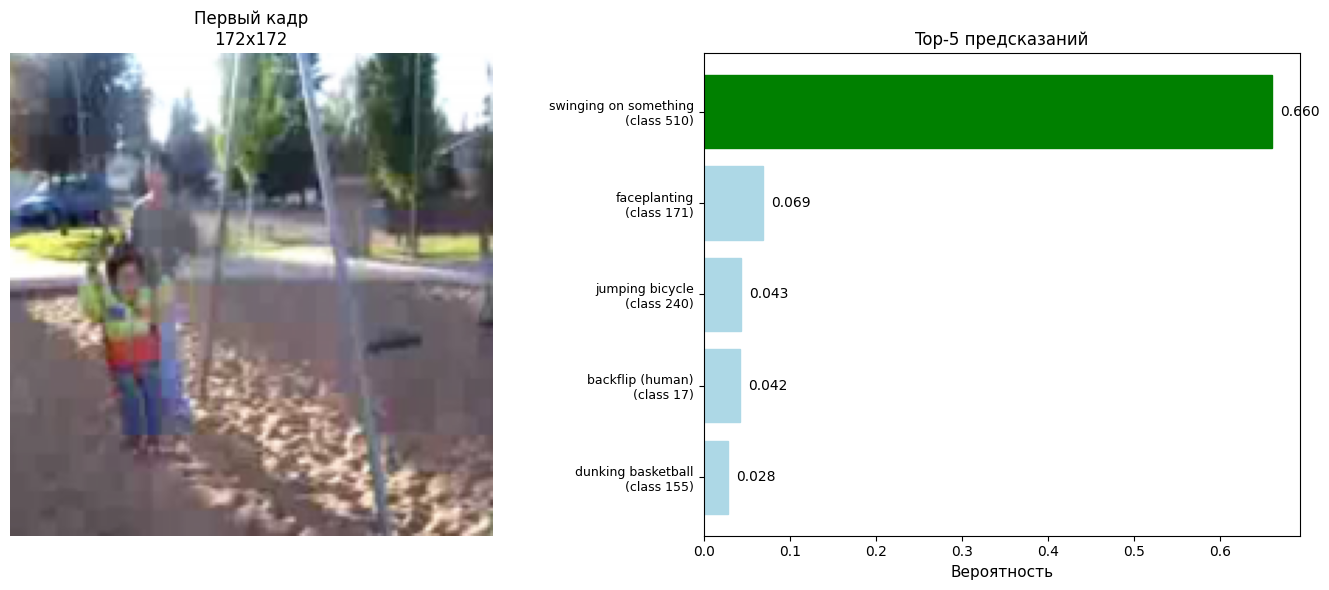


АНАЛИЗ ПРЕДСКАЗАНИЙ:
1. swinging on something
   Вероятность: 66.031%
   Уверенность: Средняя

2. faceplanting
   Вероятность: 6.858%

3. jumping bicycle
   Вероятность: 4.295%

4. backflip (human)
   Вероятность: 4.194%

5. dunking basketball
   Вероятность: 2.779%



In [18]:
def show_video_with_movinet_predictions(video_tensor, model, class_names=None, 
                                        top_k=5, device='cpu', target_batch_size=16):
    """
    Специальная функция для MoViNet с учетом требований к batch size
    """
    print(f"Входной тензор: {video_tensor.shape}")
    
    # 1. Подготавливаем видео с правильным batch size
    if len(video_tensor.shape) == 4:  # [C, T, H, W] - одно видео
        # Дублируем видео чтобы получить нужный batch size
        video_list = [video_tensor] * target_batch_size
        video_batch = torch.stack(video_list, dim=0)  # [target_batch_size, C, T, H, W]
        
    elif len(video_tensor.shape) == 5:  # [B, C, T, H, W]
        current_batch = video_tensor.shape[0]
        if current_batch < target_batch_size:
            # Дублируем последний элемент чтобы достичь нужного размера
            repeat_times = target_batch_size - current_batch
            last_video = video_tensor[-1:].repeat(repeat_times, 1, 1, 1, 1)
            video_batch = torch.cat([video_tensor, last_video], dim=0)
        elif current_batch > target_batch_size:
            # Обрезаем до нужного размера
            video_batch = video_tensor[:target_batch_size]
        else:
            video_batch = video_tensor
    
    print(f"Подготовленный batch: {video_batch.shape} (target batch size: {target_batch_size})")
    
    # 2. Предсказание модели
    model.eval()
    try:
        with torch.no_grad():
            video_batch = video_batch.to(device)
            outputs = model(video_batch)
            print(f"Выход модели: {outputs.shape}")
            
            # Берем только первое предсказание (для нашего оригинального видео)
            probs = torch.softmax(outputs, dim=1)
            top_probs, top_indices = torch.topk(probs[0:1], top_k)  # Берем только первый элемент
    
    except RuntimeError as e:
        print(f"Ошибка: {e}")
        print("\nПробуем другой batch size...")
        # Пробуем разные batch sizes
        for bs in [1, 2, 4, 8, 16, 32]:
            try:
                test_input = torch.randn(bs, 3, 16, 172, 172).to(device)
                with torch.no_grad():
                    test_output = model(test_input)
                print(f"✓ Batch size {bs} работает")
                # Используем найденный рабочий batch size
                return show_video_with_movinet_predictions(
                    video_tensor, model, class_names, top_k, device, bs
                )
            except:
                continue
        raise RuntimeError("Не удалось найти подходящий batch size")
    
    # 3. Визуализация
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # 3.1 Показываем первый кадр оригинального видео
    if len(video_tensor.shape) == 4:
        first_video = video_tensor
    else:
        first_video = video_tensor[0]
    
    first_frame = first_video[:, 0, :, :].permute(1, 2, 0).cpu().numpy()  # [H, W, C]
    
    if first_frame.max() <= 1.0:
        first_frame = (first_frame * 255).astype(np.uint8)
    
    axes[0].imshow(first_frame)
    axes[0].set_title(f"Первый кадр\n{first_frame.shape[0]}x{first_frame.shape[1]}")
    axes[0].axis('off')
    
    # 3.2 Показываем предсказания
    top_probs_np = top_probs[0].cpu().numpy()
    top_indices_np = top_indices[0].cpu().numpy()
    
    bars = axes[1].barh(range(top_k), top_probs_np)
    axes[1].set_yticks(range(top_k))
    
    # Цвета
    for i, bar in enumerate(bars):
        bar.set_color('green' if i == 0 else 'lightblue')
    
    # Подписи классов
    if class_names:
        y_labels = []
        for idx in top_indices_np:
            key = str(idx)
            if key in class_names:
                y_labels.append(f"{class_names[key]}\n(class {idx})")
            else:
                y_labels.append(f"Class {idx}")
    else:
        y_labels = [f"Class {idx}" for idx in top_indices_np]
    
    axes[1].set_yticklabels(y_labels, fontsize=9)
    axes[1].set_xlabel("Вероятность", fontsize=11)
    axes[1].set_title(f"Top-{top_k} предсказаний", fontsize=12)
    axes[1].invert_yaxis()
    
    # Значения на столбцах
    for i, prob in enumerate(top_probs_np):
        axes[1].text(prob + 0.01, i, f"{prob:.3f}", va='center')
    
    plt.tight_layout()
    plt.show()
    
    # 4. Детальная информация
    print("\n" + "="*60)
    print("АНАЛИЗ ПРЕДСКАЗАНИЙ:")
    print("="*60)
    
    for i in range(top_k):
        idx = top_indices_np[i]
        prob = top_probs_np[i]
        class_name = class_names.get(str(idx), f"Class {idx}") if class_names else f"Class {idx}"
        
        print(f"{i+1}. {class_name}")
        print(f"   Вероятность: {prob:.3%}")
        if i == 0:
            confidence = "ВЫСОКАЯ" if prob > 0.7 else "Средняя" if prob > 0.3 else "Низкая"
            print(f"   Уверенность: {confidence}")
        print()
    
    return top_probs[0], top_indices[0]

# Использование с вашей моделью
print("Визуализирую первое видео с предсказаниями...")
top_probs, top_indices = show_video_with_movinet_predictions(
    videos[0].cpu(), 
    model, 
    class_names=id2label,  # ваш словарь с классами
    device=device
)